In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/raw/redata_demanda_2024.parquet")

print("Tamaño del dataset:", df.shape)
print("Columnas:", df.columns.tolist())

display(df.head())

Tamaño del dataset: (8784, 3)
Columnas: ['datetime', 'value', 'percentage']


,datetime,value,percentage
0,2023-12-31 23:00:00+00:00,23301.083333,0.332243
1,2024-01-01 00:00:00+00:00,23409.416667,0.339385
2,2024-01-01 01:00:00+00:00,21800.416667,0.338369
3,2024-01-01 02:00:00+00:00,20052.916667,0.333965
4,2024-01-01 03:00:00+00:00,19350.583333,0.334186


In [2]:
# 1. Revisar tipos de datos
print("TIPOS DE DATOS")
print(df.dtypes)

# 2. Comprobar valores nulos
print("\nVALORES NULOS")
print(df.isnull().sum())

# 3. Comprobar filas duplicadas
print("\nFILAS DUPLICADAS")
print(df.duplicated().sum())

# 4. Revisar estadísticas de las variables numéricas
print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df[["value", "percentage"]].describe())

# 5. Comprobar el rango temporal
print("\nRANGO TEMPORAL")
print("Fecha inicial:", df["datetime"].min())
print("Fecha final:", df["datetime"].max())
print("Número de fechas distintas:", df["datetime"].nunique())

TIPOS DE DATOS
datetime      datetime64[us, UTC]
value                     float64
percentage                float64
dtype: object

VALORES NULOS
datetime      0
value         0
percentage    0
dtype: int64

FILAS DUPLICADAS
0

ESTADÍSTICAS DESCRIPTIVAS


,value,percentage
count,8784.000000,8784.000000
mean,28152.667720,0.333486
std,4291.817030,0.007825
min,18829.416667,0.317488
25%,24504.145833,0.331870
50%,28319.583333,0.333131
75%,31295.500000,0.334411
max,40113.583333,0.505288



RANGO TEMPORAL
Fecha inicial: 2023-12-31 23:00:00+00:00
Fecha final: 2024-12-31 22:00:00+00:00
Número de fechas distintas: 8784


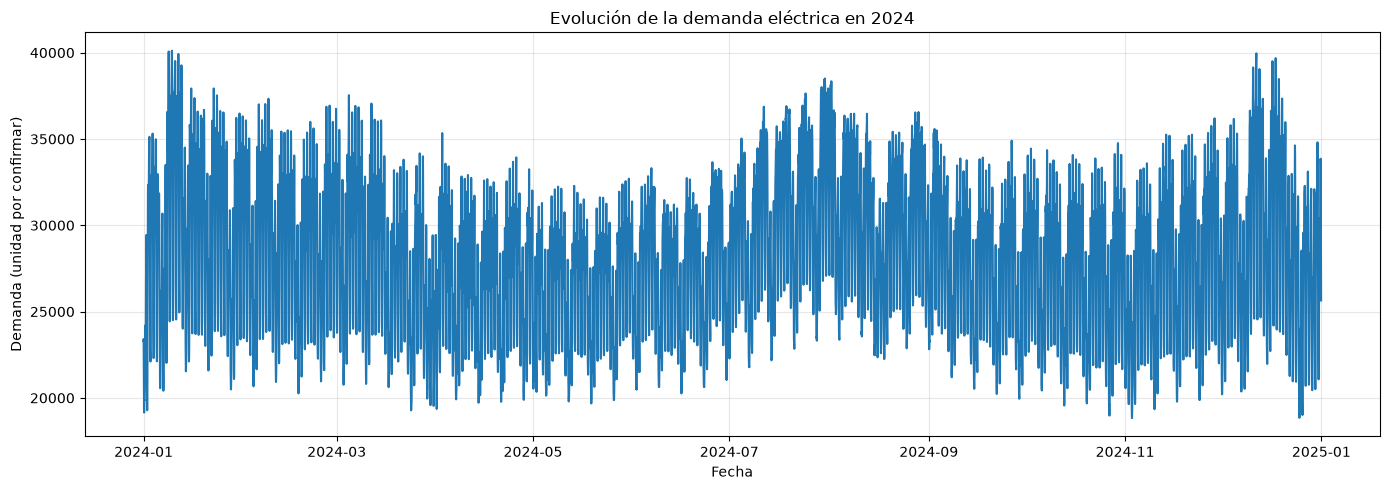

In [3]:
# Ordenar los registros cronológicamente
df = df.sort_values("datetime")

# Representar la demanda a lo largo del tiempo
plt.figure(figsize=(14, 5))
plt.plot(df["datetime"], df["value"])

plt.title("Evolución de la demanda eléctrica en 2024")
plt.xlabel("Fecha")
plt.ylabel("Demanda (unidad por confirmar)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

hora
0     23898.008652
1     23057.079690
2     22672.767304
3     22740.463570
4     23876.522313
5     25983.086066
6     28089.794399
7     29317.825820
8     29845.364299
9     29899.706967
10    29786.736339
11    29841.620219
12    29771.492031
13    29314.192395
14    28961.792122
15    29208.519353
16    29859.372951
17    31009.780965
18    32313.301457
19    33013.113616
20    31776.250455
21    29199.341302
22    26980.117942
23    25247.775046
Name: value, dtype: float64

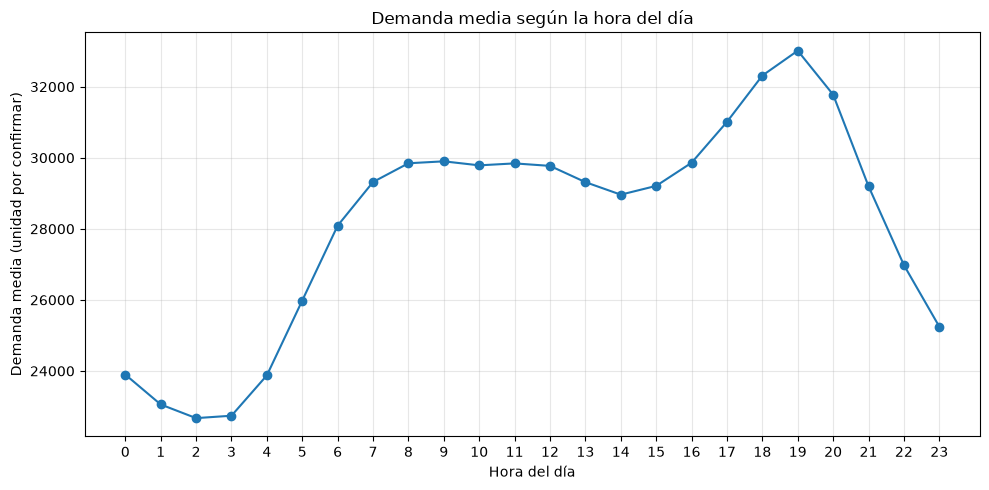

In [4]:
# Extraer la hora de cada registro
df["hora"] = df["datetime"].dt.hour

# Calcular la demanda media para cada hora
demanda_hora = df.groupby("hora")["value"].mean()

# Mostrar resultados
display(demanda_hora)

# Crear gráfico
plt.figure(figsize=(10, 5))
demanda_hora.plot(kind="line", marker="o")

plt.title("Demanda media según la hora del día")
plt.xlabel("Hora del día")
plt.ylabel("Demanda media (unidad por confirmar)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

dia_semana
Lunes        28831.386596
Martes       29502.998099
Miércoles    29482.137153
Jueves       29502.559696
Viernes      29097.749533
Sábado       26056.157252
Domingo      24560.625767
Name: value, dtype: float64

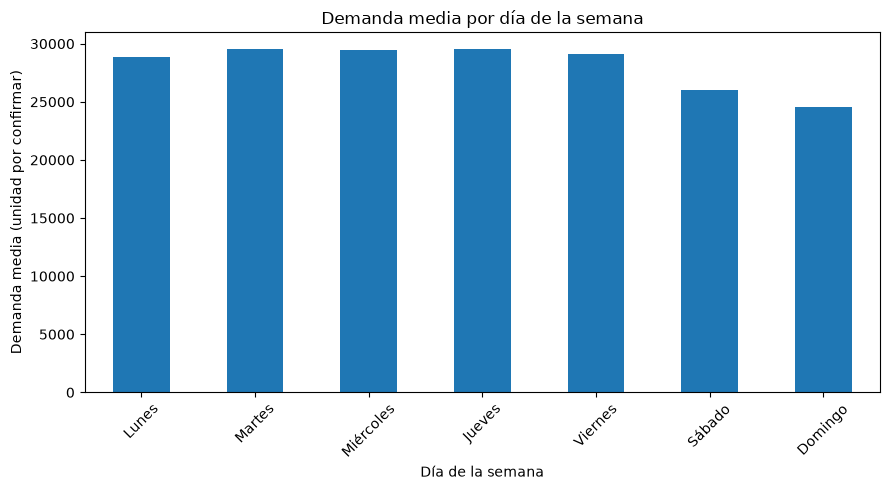

In [5]:
# Obtener el día de la semana
df["dia_semana"] = df["datetime"].dt.dayofweek

dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

demanda_dia = df.groupby("dia_semana")["value"].mean()
demanda_dia.index = demanda_dia.index.map(dias)

display(demanda_dia)

plt.figure(figsize=(9, 5))
demanda_dia.plot(kind="bar")

plt.title("Demanda media por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Demanda media (unidad por confirmar)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
# Obtener los 10 valores más altos
print("10 registros con mayor demanda:")
display(
    df.nlargest(10, "value")[["datetime", "value", "percentage"]]
)

# Obtener los 10 valores más bajos
print("10 registros con menor demanda:")
display(
    df.nsmallest(10, "value")[["datetime", "value", "percentage"]]
)

10 registros con mayor demanda:


,datetime,value,percentage
212,2024-01-09 19:00:00+00:00,40113.583333,0.332623
188,2024-01-08 19:00:00+00:00,40065.833333,0.332950
8300,2024-12-11 19:00:00+00:00,39962.000000,0.336871
260,2024-01-11 19:00:00+00:00,39923.166667,0.331310
8299,2024-12-11 18:00:00+00:00,39689.750000,0.337906
8444,2024-12-17 19:00:00+00:00,39685.333333,0.332838
187,2024-01-08 18:00:00+00:00,39648.000000,0.334797
236,2024-01-10 19:00:00+00:00,39516.333333,0.330061
8420,2024-12-16 19:00:00+00:00,39507.333333,0.332374
213,2024-01-09 20:00:00+00:00,39434.500000,0.334639


10 registros con menor demanda:


,datetime,value,percentage
7373,2024-11-03 04:00:00+00:00,18829.416667,0.336143
8621,2024-12-25 04:00:00+00:00,18847.500000,0.333663
7372,2024-11-03 03:00:00+00:00,18848.416667,0.334517
7204,2024-10-27 03:00:00+00:00,18978.416667,0.332308
8620,2024-12-25 03:00:00+00:00,18999.333333,0.334038
8644,2024-12-26 03:00:00+00:00,19010.250000,0.334789
8643,2024-12-26 02:00:00+00:00,19127.833333,0.333203
5,2024-01-01 04:00:00+00:00,19153.166667,0.333526
7371,2024-11-03 02:00:00+00:00,19161.666667,0.334516
8622,2024-12-25 05:00:00+00:00,19163.833333,0.334703


In [7]:
# Identificar los 10 valores más altos
display(
    df.nlargest(10, "value")[
        ["datetime", "value", "percentage"]
    ]
)

# Identificar los 10 valores más bajos
display(
    df.nsmallest(10, "value")[
        ["datetime", "value", "percentage"]
    ]
)

,datetime,value,percentage
212,2024-01-09 19:00:00+00:00,40113.583333,0.332623
188,2024-01-08 19:00:00+00:00,40065.833333,0.332950
8300,2024-12-11 19:00:00+00:00,39962.000000,0.336871
260,2024-01-11 19:00:00+00:00,39923.166667,0.331310
8299,2024-12-11 18:00:00+00:00,39689.750000,0.337906
8444,2024-12-17 19:00:00+00:00,39685.333333,0.332838
187,2024-01-08 18:00:00+00:00,39648.000000,0.334797
236,2024-01-10 19:00:00+00:00,39516.333333,0.330061
8420,2024-12-16 19:00:00+00:00,39507.333333,0.332374
213,2024-01-09 20:00:00+00:00,39434.500000,0.334639


,datetime,value,percentage
7373,2024-11-03 04:00:00+00:00,18829.416667,0.336143
8621,2024-12-25 04:00:00+00:00,18847.500000,0.333663
7372,2024-11-03 03:00:00+00:00,18848.416667,0.334517
7204,2024-10-27 03:00:00+00:00,18978.416667,0.332308
8620,2024-12-25 03:00:00+00:00,18999.333333,0.334038
8644,2024-12-26 03:00:00+00:00,19010.250000,0.334789
8643,2024-12-26 02:00:00+00:00,19127.833333,0.333203
5,2024-01-01 04:00:00+00:00,19153.166667,0.333526
7371,2024-11-03 02:00:00+00:00,19161.666667,0.334516
8622,2024-12-25 05:00:00+00:00,19163.833333,0.334703


In [8]:
# Calcular los cuartiles y el rango intercuartílico
Q1 = df["value"].quantile(0.25)
Q3 = df["value"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

# Identificar posibles valores extremos
anomalias = df[
    (df["value"] < limite_inferior) |
    (df["value"] > limite_superior)
]

print("Posibles valores extremos:", len(anomalias))
display(anomalias.head(10))

Q1: 24504.145833333332
Q3: 31295.5
IQR: 6791.354166666668
Límite inferior: 14317.11458333333
Límite superior: 41482.53125
Posibles valores extremos: 0


,datetime,value,percentage,hora,dia_semana


In [9]:
# Calcular la diferencia entre fechas consecutivas
diferencias = df["datetime"].sort_values().diff()

print("Intervalos entre registros:")
display(diferencias.value_counts().head(10))

print(
    "Intervalos distintos de una hora:",
    (diferencias.dropna() != pd.Timedelta(hours=1)).sum()
)

Intervalos entre registros:


datetime
0 days 01:00:00    8783
Name: count, dtype: int64

Intervalos distintos de una hora: 0


In [10]:
# Cargar los datos meteorológicos
meteo = pd.read_parquet(
    "../data/raw/openmeteo_madrid_2024.parquet"
)

print("Dimensiones:", meteo.shape)
print("\nColumnas:")
print(meteo.columns.tolist())

print("\nTipos de datos:")
meteo.info()

print("\nValores nulos:")
display(meteo.isnull().sum())

print("\nPrimeros registros:")
display(meteo.head())

Dimensiones: (8784, 2)

Columnas:
['time', 'temperature_2m']

Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype              
---  ------          --------------  -----              
 0   time            8784 non-null   datetime64[us, UTC]
 1   temperature_2m  8784 non-null   float64            
dtypes: datetime64[us, UTC](1), float64(1)
memory usage: 137.4 KB

Valores nulos:


time              0
temperature_2m    0
dtype: int64


Primeros registros:


,time,temperature_2m
0,2024-01-01 00:00:00+00:00,4.3
1,2024-01-01 01:00:00+00:00,4.1
2,2024-01-01 02:00:00+00:00,3.6
3,2024-01-01 03:00:00+00:00,3.1
4,2024-01-01 04:00:00+00:00,3.5


In [11]:
print("DEMANDA")
print("Inicio:", df["datetime"].min())
print("Fin:", df["datetime"].max())

print("\nMETEOROLOGÍA")
print("Inicio:", meteo["time"].min())
print("Fin:", meteo["time"].max())

# Comprobar cuántas fechas coinciden exactamente
fechas_demanda = set(df["datetime"])
fechas_meteo = set(meteo["time"])

print("\nFechas coincidentes:", len(fechas_demanda & fechas_meteo))
print("Fechas solo en demanda:", len(fechas_demanda - fechas_meteo))
print("Fechas solo en meteorología:", len(fechas_meteo - fechas_demanda))

DEMANDA
Inicio: 2023-12-31 23:00:00+00:00
Fin: 2024-12-31 22:00:00+00:00

METEOROLOGÍA
Inicio: 2024-01-01 00:00:00+00:00
Fin: 2024-12-31 23:00:00+00:00

Fechas coincidentes: 8783
Fechas solo en demanda: 1
Fechas solo en meteorología: 1


count    8784.000000
mean       15.824044
std         8.860741
min        -2.600000
25%         8.900000
50%        14.700000
75%        21.900000
max        40.400000
Name: temperature_2m, dtype: float64

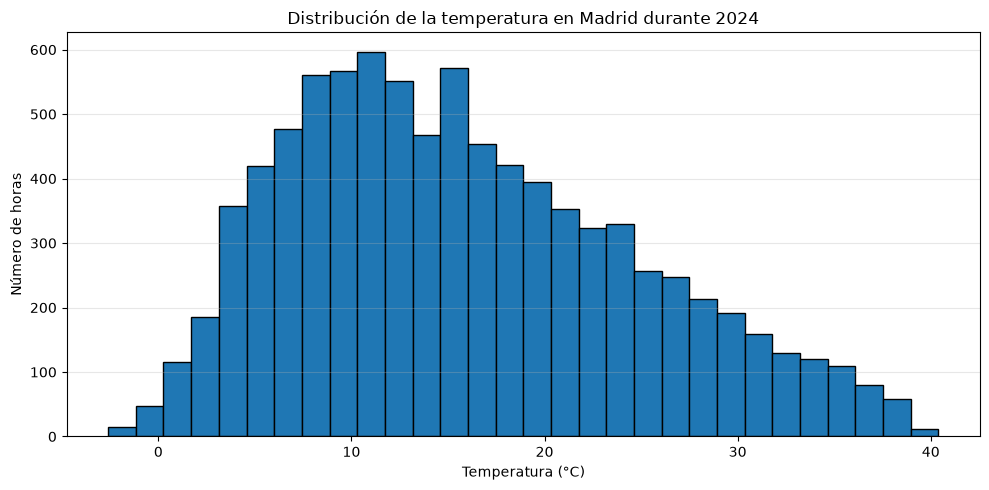

In [12]:
display(meteo["temperature_2m"].describe())

plt.figure(figsize=(10, 5))
plt.hist(meteo["temperature_2m"], bins=30, edgecolor="black")

plt.title("Distribución de la temperatura en Madrid durante 2024")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Número de horas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Preparar las columnas necesarias
demanda = df[["datetime", "value", "percentage"]].copy()

temperatura = meteo[["time", "temperature_2m"]].copy()

# Unir por fecha y hora exactas
eda = demanda.merge(
    temperatura,
    left_on="datetime",
    right_on="time",
    how="inner",
    validate="one_to_one"
)

# Eliminar la columna temporal duplicada
eda = eda.drop(columns=["time"])

print("Dimensiones del dataset combinado:", eda.shape)
print("\nValores nulos:")
print(eda.isnull().sum())

display(eda.head())

Dimensiones del dataset combinado: (8783, 4)

Valores nulos:
datetime          0
value             0
percentage        0
temperature_2m    0
dtype: int64


,datetime,value,percentage,temperature_2m
0,2024-01-01 00:00:00+00:00,23409.416667,0.339385,4.3
1,2024-01-01 01:00:00+00:00,21800.416667,0.338369,4.1
2,2024-01-01 02:00:00+00:00,20052.916667,0.333965,3.6
3,2024-01-01 03:00:00+00:00,19350.583333,0.334186,3.1
4,2024-01-01 04:00:00+00:00,19153.166667,0.333526,3.5


Correlación entre temperatura y demanda: 0.237


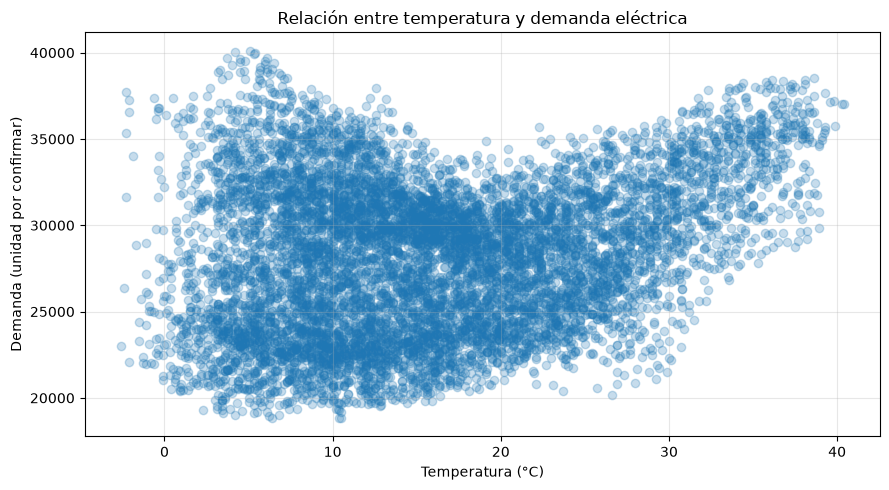

In [14]:
# Correlación lineal entre temperatura y demanda
correlacion = eda["value"].corr(eda["temperature_2m"])

print("Correlación entre temperatura y demanda:", round(correlacion, 3))

# Gráfico de dispersión
plt.figure(figsize=(9, 5))

plt.scatter(
    eda["temperature_2m"],
    eda["value"],
    alpha=0.25
)

plt.title("Relación entre temperatura y demanda eléctrica")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Demanda (unidad por confirmar)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,mean,count
intervalo_temp,,
"(-2.643, 1.7]",26875.373352,177
"(1.7, 6.0]",27595.171598,997
"(6.0, 10.3]",27971.240605,1570
"(10.3, 14.6]",27704.991743,1645
"(14.6, 18.9]",27196.002784,1437
"(18.9, 23.2]",27395.093413,1050
"(23.2, 27.5]",28298.523381,834
"(27.5, 31.8]",30192.472222,564
"(31.8, 36.1]",33013.939815,360


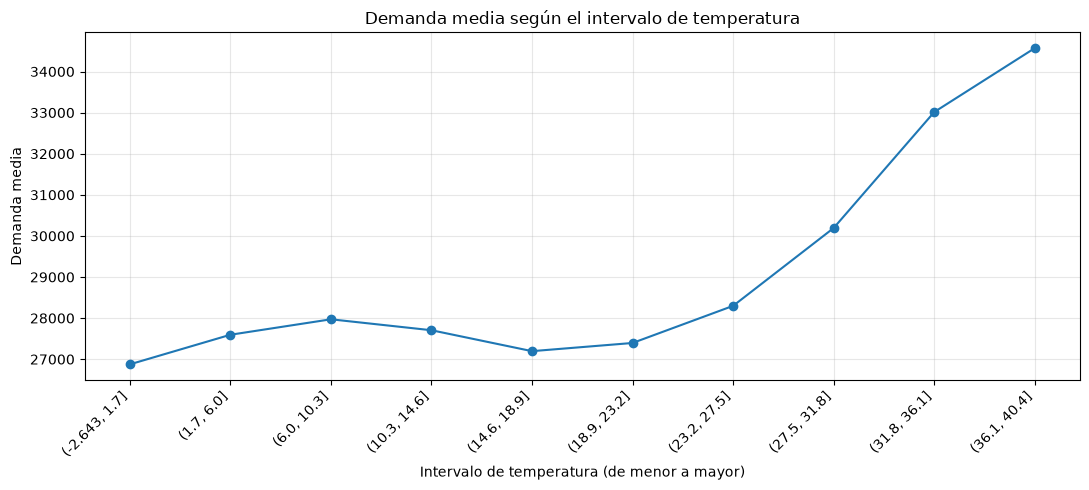

In [15]:
# Crear intervalos de temperatura
eda["intervalo_temp"] = pd.cut(
    eda["temperature_2m"],
    bins=10
)

# Calcular la demanda media por intervalo
demanda_por_temp = (
    eda.groupby("intervalo_temp", observed=True)["value"]
    .agg(["mean", "count"])
)

display(demanda_por_temp)

# Graficar los resultados
plt.figure(figsize=(11, 5))

plt.plot(
    range(len(demanda_por_temp)),
    demanda_por_temp["mean"],
    marker="o"
)

plt.title("Demanda media según el intervalo de temperatura")
plt.xlabel("Intervalo de temperatura (de menor a mayor)")
plt.ylabel("Demanda media")
plt.xticks(
    range(len(demanda_por_temp)),
    demanda_por_temp.index.astype(str),
    rotation=45,
    ha="right"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

mes
Enero         29835.075829
Febrero       28828.687261
Marzo         27488.114919
Abril         26388.555787
Mayo          26140.753920
Junio         27153.873495
Julio         30628.173499
Agosto        30096.064180
Septiembre    27624.377315
Octubre       27171.750896
Noviembre     27460.091782
Diciembre     28939.177210
Name: value, dtype: float64

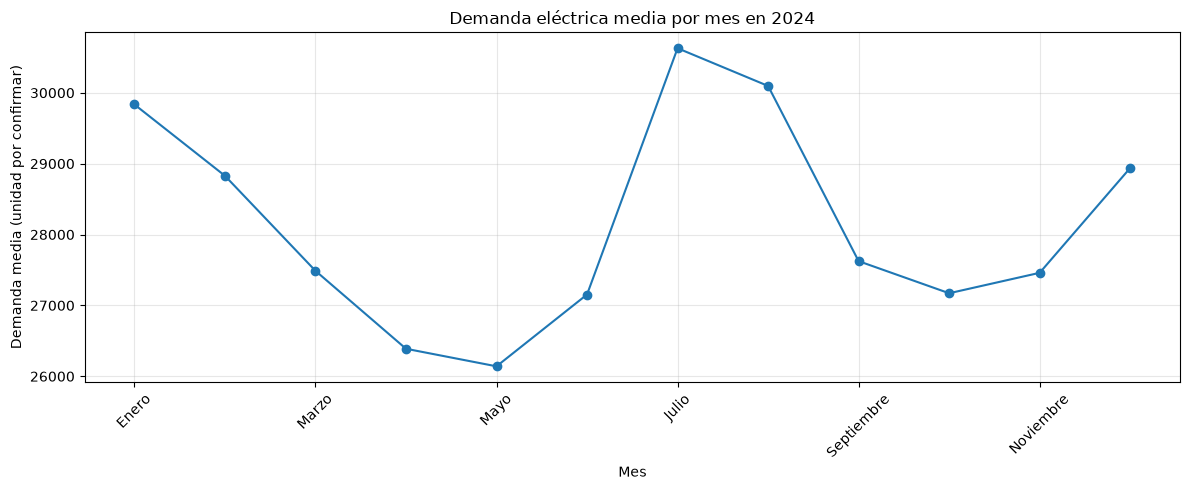

In [16]:
# Extraer el mes de cada registro
eda["mes"] = eda["datetime"].dt.month

# Calcular la demanda media mensual
demanda_mes = eda.groupby("mes")["value"].mean()

meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

demanda_mes.index = demanda_mes.index.map(meses)

display(demanda_mes)

plt.figure(figsize=(12, 5))
demanda_mes.plot(kind="line", marker="o")

plt.title("Demanda eléctrica media por mes en 2024")
plt.xlabel("Mes")
plt.ylabel("Demanda media (unidad por confirmar)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

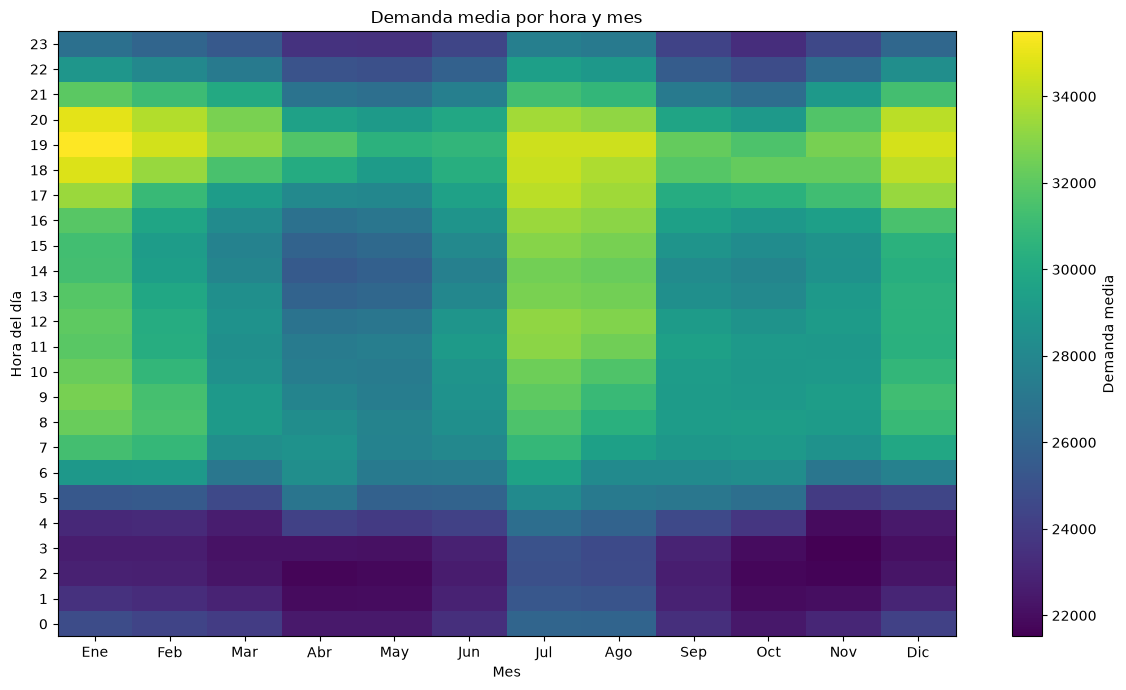

In [19]:
# Crear las variables temporales en el dataset combinado
eda["hora"] = eda["datetime"].dt.hour
eda["mes"] = eda["datetime"].dt.month

# Calcular la demanda media por hora y mes
tabla_hora_mes = eda.pivot_table(
    index="hora",
    columns="mes",
    values="value",
    aggfunc="mean"
)

# Dibujar el mapa de calor
plt.figure(figsize=(12, 7))

plt.imshow(
    tabla_hora_mes,
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Demanda media")
plt.title("Demanda media por hora y mes")
plt.xlabel("Mes")
plt.ylabel("Hora del día")

plt.xticks(
    range(12),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
     "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
)

plt.yticks(range(24), range(24))
plt.tight_layout()
plt.show()

In [20]:
# Comprobar el dataset final del EDA
print("Dimensiones:", eda.shape)
print("\nColumnas:")
print(eda.columns.tolist())

print("\nValores nulos:")
print(eda.isnull().sum())

print("\nDuplicados:")
print(eda.duplicated().sum())

display(eda.head())

Dimensiones: (8783, 7)

Columnas:
['datetime', 'value', 'percentage', 'temperature_2m', 'intervalo_temp', 'mes', 'hora']

Valores nulos:
datetime          0
value             0
percentage        0
temperature_2m    0
intervalo_temp    0
mes               0
hora              0
dtype: int64

Duplicados:
0


,datetime,value,percentage,temperature_2m,intervalo_temp,mes,hora
0,2024-01-01 00:00:00+00:00,23409.416667,0.339385,4.3,"(1.7, 6.0]",1,0
1,2024-01-01 01:00:00+00:00,21800.416667,0.338369,4.1,"(1.7, 6.0]",1,1
2,2024-01-01 02:00:00+00:00,20052.916667,0.333965,3.6,"(1.7, 6.0]",1,2
3,2024-01-01 03:00:00+00:00,19350.583333,0.334186,3.1,"(1.7, 6.0]",1,3
4,2024-01-01 04:00:00+00:00,19153.166667,0.333526,3.5,"(1.7, 6.0]",1,4


In [21]:
# Seleccionar y ordenar las columnas finales
eda_final = eda[
    [
        "datetime",
        "value",
        "percentage",
        "temperature_2m",
        "mes",
        "hora"
    ]
].copy()

# Ordenar cronológicamente
eda_final = eda_final.sort_values("datetime").reset_index(drop=True)

# Comprobaciones finales
print("Dimensiones:", eda_final.shape)
print("Nulos:", eda_final.isnull().sum().sum())
print("Duplicados:", eda_final.duplicated().sum())

display(eda_final.head())

Dimensiones: (8783, 6)
Nulos: 0
Duplicados: 0


,datetime,value,percentage,temperature_2m,mes,hora
0,2024-01-01 00:00:00+00:00,23409.416667,0.339385,4.3,1,0
1,2024-01-01 01:00:00+00:00,21800.416667,0.338369,4.1,1,1
2,2024-01-01 02:00:00+00:00,20052.916667,0.333965,3.6,1,2
3,2024-01-01 03:00:00+00:00,19350.583333,0.334186,3.1,1,3
4,2024-01-01 04:00:00+00:00,19153.166667,0.333526,3.5,1,4


In [22]:
from pathlib import Path

# Crear carpeta de resultados si no existe
carpeta = Path("../data/processed")
carpeta.mkdir(parents=True, exist_ok=True)

# Guardar el dataset combinado
ruta = carpeta / "demanda_eda_2024.parquet"
eda_final.to_parquet(ruta, index=False)

print("Dataset guardado en:", ruta)

Dataset guardado en: ..\data\processed\demanda_eda_2024.parquet


In [6]:
# ============================================================
# 1. IMPORTAR LIBRERÍAS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ============================================================
# 2. CARGAR LOS DATOS ORIGINALES
# ============================================================

carpeta_datos = Path("../data/raw")

archivo_demanda = carpeta_datos / "redata_demanda_2024.parquet"
archivo_meteo = carpeta_datos / "openmeteo_madrid_2024.parquet"

if not archivo_demanda.exists():
    raise FileNotFoundError(
        f"No se encuentra el archivo de demanda: {archivo_demanda.resolve()}"
    )

if not archivo_meteo.exists():
    raise FileNotFoundError(
        f"No se encuentra el archivo meteorológico: {archivo_meteo.resolve()}"
    )

df = pd.read_parquet(archivo_demanda)
meteo = pd.read_parquet(archivo_meteo)

df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
meteo["time"] = pd.to_datetime(meteo["time"], utc=True)

print("Demanda cargada:", df.shape)
print("Meteorología cargada:", meteo.shape)


# ============================================================
# 3. UNIR DEMANDA Y METEOROLOGÍA
# ============================================================

eda = df.merge(
    meteo[["time", "temperature_2m"]],
    left_on="datetime",
    right_on="time",
    how="inner",
    validate="one_to_one"
)

eda = eda.drop(columns=["time"])

eda["hora"] = eda["datetime"].dt.hour
eda["mes"] = eda["datetime"].dt.month

# Crear el conjunto de datos que utilizaremos
eda_final = eda[
    ["datetime", "value", "percentage", "temperature_2m", "mes", "hora"]
].copy()

eda_final = (
    eda_final
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("\nDatos preparados:", eda_final.shape)
display(eda_final.head())


# ============================================================
# 4. CREAR LAS VARIABLES PARA LA PREDICCIÓN
# ============================================================

datos = eda_final.copy()

datos["datetime"] = pd.to_datetime(datos["datetime"], utc=True)
datos = datos.sort_values("datetime").reset_index(drop=True)

datos["hora"] = datos["datetime"].dt.hour
datos["dia_semana"] = datos["datetime"].dt.dayofweek
datos["mes"] = datos["datetime"].dt.month

# Demanda conocida en la hora actual y horas anteriores
datos["demanda_lag_1"] = datos["value"]
datos["demanda_lag_24"] = datos["value"].shift(23)
datos["demanda_lag_168"] = datos["value"].shift(167)

# Media de las últimas 24 horas, incluida la hora actual
datos["media_24h"] = datos["value"].rolling(24).mean()

# Objetivo: demanda de la siguiente hora
datos["objetivo"] = datos["value"].shift(-1)

# Eliminar filas sin historial suficiente o sin objetivo
datos = datos.dropna().reset_index(drop=True)

variables = [
    "hora",
    "dia_semana",
    "mes",
    "temperature_2m",
    "demanda_lag_1",
    "demanda_lag_24",
    "demanda_lag_168",
    "media_24h"
]

X = datos[variables]
y = datos["objetivo"]

print("\nFilas utilizables:", len(datos))
print("Variables de entrada:", variables)
print("Objetivo: demanda de la siguiente hora")


# ============================================================
# 5. DIVIDIR LOS DATOS CRONOLÓGICAMENTE
# ============================================================

corte = int(len(datos) * 0.8)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

print("\nRegistros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Inicio del periodo de prueba:",
      datos["datetime"].iloc[corte])


# ============================================================
# 6. ENTRENAR EL MODELO
# ============================================================

modelo = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

modelo.fit(X_train, y_train)

print("\nModelo entrenado correctamente.")


# ============================================================
# 7. EVALUAR EL MODELO
# ============================================================

predicciones = modelo.predict(X_test)

mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))

# Comparar con una predicción sencilla:
# asumir que la próxima hora tendrá la misma demanda que la actual
referencia = X_test["demanda_lag_1"].to_numpy()

mae_referencia = mean_absolute_error(y_test, referencia)
rmse_referencia = np.sqrt(mean_squared_error(y_test, referencia))

print("\n--- RESULTADOS ---")
print(f"MAE del modelo:       {mae:.2f}")
print(f"RMSE del modelo:      {rmse:.2f}")
print(f"MAE de referencia:    {mae_referencia:.2f}")
print(f"RMSE de referencia:   {rmse_referencia:.2f}")

if mae < mae_referencia and rmse < rmse_referencia:
    print("El modelo mejora las dos métricas de referencia.")
else:
    print("El modelo no mejora ambas métricas; conviene revisarlo.")


# ============================================================
# 8. IMPORTANCIA DE LAS VARIABLES
# ============================================================

importancias = pd.Series(
    modelo.feature_importances_,
    index=variables
).sort_values(ascending=False)

print("\n--- IMPORTANCIA DE LAS VARIABLES ---")
display(importancias.to_frame("importancia"))


# ============================================================
# 9. GUARDAR EL MODELO ENTRENADO
# ============================================================

carpeta_modelos = Path("../models")
carpeta_modelos.mkdir(parents=True, exist_ok=True)

artefacto = {
    "modelo": modelo,
    "variables": variables,
    "objetivo": "demanda_siguiente_hora",
    "horizonte_horas": 1,
    "version": "0.1"
}

ruta_modelo = carpeta_modelos / "modelo_demanda_v01.joblib"

joblib.dump(artefacto, ruta_modelo)

print("\nModelo guardado correctamente en:")
print(ruta_modelo.resolve())

Demanda cargada: (8784, 3)
Meteorología cargada: (8784, 2)

Datos preparados: (8783, 6)


,datetime,value,percentage,temperature_2m,mes,hora
0,2024-01-01 00:00:00+00:00,23409.416667,0.339385,4.3,1,0
1,2024-01-01 01:00:00+00:00,21800.416667,0.338369,4.1,1,1
2,2024-01-01 02:00:00+00:00,20052.916667,0.333965,3.6,1,2
3,2024-01-01 03:00:00+00:00,19350.583333,0.334186,3.1,1,3
4,2024-01-01 04:00:00+00:00,19153.166667,0.333526,3.5,1,4



Filas utilizables: 8615
Variables de entrada: ['hora', 'dia_semana', 'mes', 'temperature_2m', 'demanda_lag_1', 'demanda_lag_24', 'demanda_lag_168', 'media_24h']
Objetivo: demanda de la siguiente hora

Registros de entrenamiento: 6892
Registros de prueba: 1723
Inicio del periodo de prueba: 2024-10-21 03:00:00+00:00

Modelo entrenado correctamente.

--- RESULTADOS ---
MAE del modelo:       500.21
RMSE del modelo:      703.51
MAE de referencia:    1133.02
RMSE de referencia:   1530.76
El modelo mejora las dos métricas de referencia.

--- IMPORTANCIA DE LAS VARIABLES ---


,importancia
demanda_lag_1,0.831227
demanda_lag_168,0.105034
hora,0.041074
demanda_lag_24,0.011885
temperature_2m,0.003833
media_24h,0.003240
dia_semana,0.001933
mes,0.001773



Modelo guardado correctamente en:
C:\Users\jafcp\Desktop\prediccion-electricidad-main\models\modelo_demanda_v01.joblib


In [ ]:
# Documentación técnica del modelo de predicción de demanda eléctrica

**Versión:** 0.1  
**Tipo de modelo:** Aprendizaje automático supervisado — regresión  
**Algoritmo:** Random Forest Regressor  
**Objetivo:** Predecir la demanda eléctrica de la siguiente hora.

## 1. Descripción general

El proyecto desarrolla un modelo de aprendizaje automático capaz de estimar la demanda eléctrica correspondiente a la siguiente hora a partir de datos históricos de demanda, variables temporales y temperatura.

Para construir el conjunto de datos se combinan dos fuentes: los registros históricos de demanda eléctrica y los datos meteorológicos horarios de Madrid. Ambas fuentes se unen mediante la fecha y hora, conservando únicamente los registros que coinciden.

El modelo utiliza el algoritmo Random Forest Regressor, que combina múltiples árboles de decisión para generar una predicción numérica.

## 2. Objetivo del modelo

El objetivo es estimar la demanda eléctrica de la hora inmediatamente posterior a la última observación disponible.

Por ejemplo, si se dispone de los datos correspondientes a las 18:00, el modelo estima la demanda de las 19:00.

La variable que se desea predecir es `objetivo`, creada desplazando una posición hacia atrás la columna de demanda (`value`) para asociar cada registro con la demanda de la siguiente hora.

## 3. Variables de entrada

El modelo utiliza ocho variables de entrada.

| Variable | Descripción |
|---|---|
| `hora` | Hora del día, de 0 a 23. |
| `dia_semana` | Día de la semana, de 0 (lunes) a 6 (domingo). |
| `mes` | Mes del año, de 1 a 12. |
| `temperature_2m` | Temperatura registrada a dos metros de altura, en grados Celsius. |
| `demanda_lag_1` | Demanda eléctrica de la hora actual. |
| `demanda_lag_24` | Demanda de aproximadamente el mismo horario del día anterior. |
| `demanda_lag_168` | Demanda de aproximadamente el mismo horario de la semana anterior. |
| `media_24h` | Media de la demanda de las últimas 24 observaciones, incluida la actual. |

Estas variables permiten al modelo identificar patrones horarios, semanales y estacionales, además de relacionar la demanda reciente con las condiciones meteorológicas.

## 4. Variable objetivo

La variable objetivo se denomina `objetivo`.

Representa el valor de demanda eléctrica correspondiente a la siguiente hora.

- **Tipo de dato:** numérico continuo.
- **Problema:** regresión.
- **Horizonte de predicción:** una hora.
- **Unidad:** la misma unidad en la que está expresada la columna original `value` del conjunto de datos.

La unidad concreta debe confirmarse en la fuente original de los datos.

## 5. Preparación de los datos

Antes del entrenamiento se realizan las siguientes operaciones:

1. Carga de los archivos de demanda y meteorología en formato Parquet.
2. Conversión de las fechas a un formato temporal compatible.
3. Unión de ambas fuentes mediante la fecha y hora.
4. Creación de variables temporales.
5. Generación de variables históricas de demanda.
6. Cálculo de la media móvil de 24 horas.
7. Creación de la variable objetivo mediante el desplazamiento de la demanda una hora.
8. Eliminación de los registros que no tienen suficiente historial o carecen de objetivo.

Los datos se ordenan cronológicamente para mantener la secuencia temporal.

## 6. Entrenamiento y evaluación

El conjunto de datos se divide cronológicamente:

- **80 %:** entrenamiento del modelo.
- **20 %:** evaluación con datos posteriores a los utilizados en el entrenamiento.

No se realiza una división aleatoria, ya que se trata de una serie temporal y se debe respetar el orden cronológico.

La configuración utilizada es:

- `n_estimators = 200`: número de árboles.
- `max_depth = 15`: profundidad máxima de cada árbol.
- `min_samples_leaf = 2`: mínimo de observaciones por hoja.
- `random_state = 42`: semilla para facilitar la reproducibilidad.
- `n_jobs = -1`: utilización de los procesadores disponibles para acelerar el entrenamiento.

## 7. Métricas de evaluación

Para evaluar el rendimiento se calculan dos métricas:

**MAE (Mean Absolute Error):** mide el error absoluto medio entre la demanda real y la predicha. Cuanto menor sea, mejor.

**RMSE (Root Mean Squared Error):** mide la raíz del error cuadrático medio y penaliza especialmente los errores grandes. Cuanto menor sea, mejor.

Además, se compara el modelo con una predicción de referencia que supone que la demanda de la siguiente hora será igual a la demanda actual.

Esta comparación permite comprobar si el modelo aporta una mejora frente a una estimación sencilla. Los resultados numéricos deben completarse después de ejecutar el entrenamiento.

## 8. Formato de entrada

Para generar una predicción, el modelo necesita un registro con las ocho variables de entrada, en el mismo orden utilizado durante el entrenamiento.

Ejemplo ilustrativo en formato JSON:

```json
{
  "hora": 18,
  "dia_semana": 0,
  "mes": 1,
  "temperature_2m": 12.5,
  "demanda_lag_1": 30000.0,
  "demanda_lag_24": 28500.0,
  "demanda_lag_168": 29000.0,
  "media_24h": 28000.0
}
```

Los valores del ejemplo son ficticios y solo muestran la estructura esperada.

La temperatura utilizada debe corresponder a información disponible en el momento de realizar la predicción. Para una previsión operativa, se debe utilizar una temperatura prevista para la hora objetivo si la temperatura observada todavía no está disponible.

## 9. Formato de salida

El modelo devuelve un valor numérico continuo que representa la demanda eléctrica estimada para la siguiente hora.

Ejemplo ilustrativo de respuesta:

```json
{
  "objetivo": "demanda_siguiente_hora",
  "horizonte_horas": 1,
  "prediccion": 31500.75,
  "version_modelo": "0.1"
}
```

El valor de `prediccion` es ficticio. El código actual genera un valor numérico mediante `modelo.predict()`; el objeto JSON mostrado es un formato propuesto para documentar una futura integración.

## 10. Almacenamiento del modelo

Una vez entrenado, el modelo se guarda mediante la biblioteca `joblib` en el archivo:

`../models/modelo_demanda_v01.joblib`

El archivo contiene un diccionario con:

- El modelo entrenado.
- La lista de variables de entrada.
- El nombre del objetivo.
- El horizonte de predicción.
- La versión del modelo.

Esto permite recuperar posteriormente el modelo sin tener que repetir el entrenamiento, siempre que se disponga de un entorno compatible.

## 11. Devolución e integración de resultados

En la versión actual, el modelo se ejecuta desde un cuaderno de Jupyter. Las predicciones y las métricas se muestran en pantalla, y el modelo entrenado se guarda en un archivo.

Todavía no se ha implementado una API ni un servicio que reciba peticiones externas y devuelva respuestas JSON automáticamente.

Como posible ampliación, se puede desarrollar una API con FastAPI que reciba las ocho variables, valide los datos, ejecute la predicción y devuelva la demanda estimada junto con el horizonte y la versión del modelo.

## 12. Limitaciones y mejoras futuras

- La temperatura debe estar disponible en el momento de predecir o proceder de una previsión meteorológica.
- El modelo se entrena con datos de un único año, por lo que conviene probarlo con otros periodos.
- Se recomienda comparar diferentes algoritmos y ajustar sus parámetros.
- Las métricas de evaluación deben revisarse antes de utilizar el modelo en un entorno real.
- Se deben controlar las unidades, las fechas, los valores ausentes y la coherencia de las variables de entrada.
- La importancia de las variables indica su contribución al funcionamiento del Random Forest, pero no demuestra causalidad.

## 13. Resumen

El sistema utiliza un Random Forest Regressor para estimar la demanda eléctrica de la siguiente hora. Se alimenta de variables temporales, temperatura y demanda histórica; se entrena con el 80 % de los datos en orden cronológico y se evalúa con el 20 % restante. El resultado es una estimación numérica que se muestra en Jupyter, mientras que el modelo entrenado y su configuración se almacenan en formato Joblib para facilitar su reutilización.


In [3]:
import pandas as pd

carpeta_datos = Path("../data/raw")

df = pd.read_parquet(carpeta_datos / "redata_demanda_2024.parquet")
meteo = pd.read_parquet(carpeta_datos / "openmeteo_madrid_2024.parquet")

df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
meteo["time"] = pd.to_datetime(meteo["time"], utc=True)

eda = pd.merge(
    df,
    meteo[["time", "temperature_2m"]],
    left_on="datetime",
    right_on="time",
    how="inner",
    validate="one_to_one"
)

eda = eda.drop(columns=["time"])

eda["mes"] = eda["datetime"].dt.month
eda["hora"] = eda["datetime"].dt.hour

eda_final = eda[
    ["datetime", "value", "percentage", "temperature_2m", "mes", "hora"]
].copy()

eda_final = eda_final.sort_values("datetime").reset_index(drop=True)

print("Datos preparados:", eda_final.shape)
display(eda_final.head())

Datos preparados: (8783, 6)


,datetime,value,percentage,temperature_2m,mes,hora
0,2024-01-01 00:00:00+00:00,23409.416667,0.339385,4.3,1,0
1,2024-01-01 01:00:00+00:00,21800.416667,0.338369,4.1,1,1
2,2024-01-01 02:00:00+00:00,20052.916667,0.333965,3.6,1,2
3,2024-01-01 03:00:00+00:00,19350.583333,0.334186,3.1,1,3
4,2024-01-01 04:00:00+00:00,19153.166667,0.333526,3.5,1,4


In [4]:
from pathlib import Path

carpeta_procesados = Path("../data/processed")
carpeta_procesados.mkdir(parents=True, exist_ok=True)

ruta_datos = carpeta_procesados / "demanda_eda_2024.parquet"

eda_final.to_parquet(ruta_datos, index=False)

print("Base de datos guardada correctamente:")
print(ruta_datos.resolve())
print("Filas y columnas:", eda_final.shape)

Base de datos guardada correctamente:
C:\Users\jafcp\Desktop\prediccion-electricidad-main\data\processed\demanda_eda_2024.parquet
Filas y columnas: (8783, 6)


In [7]:
from pathlib import Path

archivos = [
    Path("../data/processed/demanda_eda_2024.parquet"),
    Path("../models/modelo_demanda_v01.joblib")
]

for archivo in archivos:
    print(
        "OK" if archivo.exists() else "FALTA",
        archivo.resolve()
    )

OK C:\Users\jafcp\Desktop\prediccion-electricidad-main\data\processed\demanda_eda_2024.parquet
OK C:\Users\jafcp\Desktop\prediccion-electricidad-main\models\modelo_demanda_v01.joblib
